In [1]:
import sys, json, glob
from pathlib import Path
ROOT = Path.cwd(); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import display, Image, Markdown
from src.common import *
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60); pd.set_option("display.float_format", lambda v: f"{v:.4f}")
def csv(name, **kw): return pd.read_csv(RES / name, **kw)

# 1. Goal
Detect attacks in IoT network traffic (CICIoT2023) and compare Decision Tree, Random Forest, XGBoost and an MLP on **detection quality (macro F1 is the main metric)** and **resource use** (model size, peak RAM, CPU, batch-1 latency, batch-1024 throughput). Then build reduced versions and compare each with its original.
All code lives in `src/`, `bench.py`, `verify.py`; this notebook only imports it and shows the saved outputs. Numbers shown here are read from the CSV/JSON files in `results/`.

## 2. Dataset
CICIoT2023 `MERGED_CSV/Merged*.csv` (63 files, 39 numeric flow features + `Label`). Used in place, streamed in chunks (never fully loaded).

In [2]:
print("Sampling rule (src/data.py): pass A counts rows per label; pass B draws an exact stratified sample (seeded, seed 42, float32).")
print("  * labels with < 30,000 rows in total: ALL rows kept")
print("  * other labels: proportional share of (1,000,000 - rows kept above), with a floor of 10,000 rows (or all rows if fewer)")
display(csv("sampling_counts.csv", index_col=0))

Sampling rule (src/data.py): pass A counts rows per label; pass B draws an exact stratified sample (seeded, seed 42, float32).
  * labels with < 30,000 rows in total: ALL rows kept
  * other labels: proportional share of (1,000,000 - rows kept above), with a floor of 10,000 rows (or all rows if fewer)


,before,after
Label,,
BACKDOOR_MALWARE,3078,3078
BENIGN,1051373,21329
BROWSERHIJACKING,5630,5630
COMMANDINJECTION,5168,5168
DDOS-ACK_FRAGMENTATION,272793,10000
DDOS-HTTP_FLOOD,27597,27597
DDOS-ICMP_FLOOD,6893259,139844
DDOS-ICMP_FRAGMENTATION,433157,10000
DDOS-PSHACK_FLOOD,3920372,79533


The sample keeps rare attacks whole and thins the huge DDoS/DoS classes, so class balance in the sample differs from the real traffic (limitation). Benign is only ~2.8% of the sample. TON_IoT and N-BaIoT are **planned work** (their files are not present locally; nothing was downloaded).

## 3. Inspection

In [3]:
print(json.dumps(jload(RES / "inspect_summary.json"), indent=1))
display(csv("inspect_dtypes.csv", index_col=0).value_counts().rename("n_columns").to_frame())
display(csv("inspect_columns.csv", index_col=0).describe().T)
display(csv("inspect_label_counts.csv", index_col=0).T)

{
 "rows": 1055885,
 "columns": 40,
 "label_column": "Label",
 "n_labels": 35,
 "missing_total": 193,
 "infinite_total": 25,
 "constant_columns": [],
 "duplicate_rows": 238732,
 "identifier_columns_present": []
}


,n_columns
dtype,
float32,39
str,1


,count,mean,std,min,25%,50%,75%,max
missing,39.0000,4.9487,6.3865,0.0000,2.0000,3.0000,7.0000,31.0000
infinite,39.0000,0.6410,4.0032,0.0000,0.0000,0.0000,0.0000,25.0000
nunique,39.0000,25686.5641,63689.5536,5.0000,100.5000,200.0000,1094.5000,232169.0000


Label,DDOS-ICMP_FLOOD,DDOS-UDP_FLOOD,DDOS-TCP_FLOOD,DDOS-PSHACK_FLOOD,DDOS-SYN_FLOOD,DDOS-RSTFINFLOOD,DDOS-SYNONYMOUSIP_FLOOD,DOS-UDP_FLOOD,DOS-TCP_FLOOD,DOS-SYN_FLOOD,DDOS-HTTP_FLOOD,DDOS-SLOWLORIS,BENIGN,MIRAI-GREETH_FLOOD,MIRAI-UDPPLAIN,MIRAI-GREIP_FLOOD,DICTIONARYBRUTEFORCE,DDOS-ICMP_FRAGMENTATION,RECON-HOSTDISCOVERY,MITM-ARPSPOOFING,DDOS-UDP_FRAGMENTATION,DOS-HTTP_FLOOD,DNS_SPOOFING,VULNERABILITYSCAN,RECON-PORTSCAN,RECON-OSSCAN,DDOS-ACK_FRAGMENTATION,BROWSERHIJACKING,COMMANDINJECTION,SQLINJECTION,XSS,BACKDOOR_MALWARE,RECON-PINGSWEEP,UPLOADING_ATTACK,NAN
count,139844,105108,87358,79533,78838,78568,69902,64458,51899,39401,27597,22400,21329,19260,17299,14600,12522,10000,10000,10000,10000,10000,10000,10000,10000,10000,10000,5630,5168,5022,3705,3078,2161,1196,9


No IP, port or timestamp columns exist in the Merged files (so none were dropped). A few NaN / infinite values and many duplicate rows were found in the sample; no column is constant.

## 4. Cleaning

In [4]:
print((RES / "cleaning_log.md").read_text())
display(csv("clean_class_counts.csv", index_col=0).T)
display(csv("label_mapping.csv").groupby("category").label.apply(list).to_frame())

# Cleaning log (auto-generated)
1. Loaded sampled data (float32): 1055885 rows x 40 cols. Identifier columns (IP/port/timestamp): none present (results/inspect_summary.json).
2. Dropped rows with a missing label (read as 'NAN'): 9.
3. Replaced +/-inf with NaN. Rows with any NaN: 25.
4. Missing-value policy: drop rows with any NaN (synopsis: drop rows with missing values). Remaining 1055851.
5. Removed exact duplicate rows (features+label) BEFORE split: 238729 removed, 817122 remain.
6. Dropped rows whose identical feature vector has conflicting task labels (8-class category; binary is implied): 52116 removed, 765006 remain.
7. Same feature vector with different fine labels but the same category: kept first, so no identical feature vectors remain (prevents cross-split leakage): 6092 removed, 758914 remain.
8. Dropped constant columns: [].
9. Built y_binary (0=Benign, 1=Attack), y_multi (8 classes, results/label_mapping.csv) and kept y_fine (original label).
10. Saved data_processed/clea

y_multi,DDoS,DoS,Mirai,Recon,Web-based,Benign,Spoofing,Brute force
count,476872,112584,50997,41815,23632,21293,19213,12508


,label
category,
Benign,"[BENIGN, BENIGNTRAFFIC]"
Brute force,[DICTIONARYBRUTEFORCE]
DDoS,"[DDOS-RSTFINFLOOD, DDOS-PSHACK_FLOOD, DDOS-SYN..."
DoS,"[DOS-UDP_FLOOD, DOS-SYN_FLOOD, DOS-TCP_FLOOD, ..."
Mirai,"[MIRAI-GREETH_FLOOD, MIRAI-UDPPLAIN, MIRAI-GRE..."
Recon,"[RECON-HOSTDISCOVERY, RECON-OSSCAN, RECON-PORT..."
Spoofing,"[MITM-ARPSPOOFING, DNS_SPOOFING]"
Web-based,"[SQLINJECTION, COMMANDINJECTION, BACKDOOR_MALW..."


Duplicates are removed **before** the split, then rows whose identical feature vector has conflicting task labels, then remaining identical vectors, so no identical feature row can sit in two splits (checked in `verify.py`). The conflicting-label removal shows that some DoS/DDoS (and benign/attack) flows are indistinguishable with these features.

## 5. Split

In [5]:
ix = np.load(PROC / "split.npz"); df = pd.read_parquet(PROC / "clean.parquet", columns=["y_multi", "y_binary"])
print({k: len(ix[k]) for k in ("train", "val", "test")}, "seed", SEED)
display(pd.DataFrame({k: df.y_multi.iloc[ix[k]].value_counts(normalize=True) * 100 for k in ("train", "val", "test")}).round(3).rename_axis("% per class"))
print((RES / "split_note.txt").read_text())

{'train': 531239, 'val': 113837, 'test': 113838} seed 42


,train,val,test
% per class,,,
DDoS,62.8360,62.8360,62.8360
DoS,14.8350,14.8340,14.8350
Mirai,6.7200,6.7190,6.7200
Recon,5.5100,5.5110,5.5100
Web-based,3.1140,3.1140,3.1140
Benign,2.8060,2.8060,2.8060
Spoofing,2.5320,2.5320,2.5320
Brute force,1.6480,1.6480,1.6480


classes with <10 rows (cannot stratify safely): {}
sizes train/val/test = 531239/113837/113838



One 70/15/15 split stratified on the 8-class label, shared by the binary and multiclass tasks and by every model. The StandardScaler is fitted on train only (`models/scaler.npz`, used by the MLP, distillation and quantization calibration); trees use raw features.

## 6. Baseline training

In [6]:
cfg = jload(RES / "baseline_config.json")
display(pd.DataFrame([{"model": k, "chosen": str(v["chosen"]), "val_macro_f1": v["val_macro_f1"], "train_time_s": v["train_time_s"], "n_trials": len(v["trials"])} for k, v in cfg.items()]))

,model,chosen,val_macro_f1,train_time_s,n_trials
0,dt_binary,"{'class_weight': None, 'max_depth': 20}",0.7793,1.8920,6
1,rf_binary,"{'class_weight': None, 'n_estimators': 100}",0.8037,15.0025,2
2,xgb_binary,"{'weighted': False, 'max_depth': 10, 'n_estima...",0.8172,6.1907,8
3,mlp_binary,"{'weighted': False, 'hidden': [128, 64]}",0.7816,62.7144,2
4,dt_multi,"{'class_weight': None, 'max_depth': 20}",0.7069,6.8533,6
5,rf_multi,"{'class_weight': 'balanced_subsample', 'n_esti...",0.7407,34.3888,2
6,xgb_multi,"{'weighted': False, 'max_depth': 10, 'n_estima...",0.7512,53.2830,8
7,mlp_multi,"{'weighted': False, 'hidden': [128, 64]}",0.7084,87.1311,2


Light tuning on the **validation set only** (class-weighted vs unweighted included, time budget per model). Full trial lists are in `results/baseline_config.json`.

## 7. Evaluation (test set, each frozen model scored once)

,task,macro_f1,accuracy,precision,recall,fpr
model_id,,,,,,
dt_binary,binary,0.7854,0.9767,0.7873,0.7836,0.4211
rf_binary,binary,0.8021,0.9813,0.8577,0.7622,0.4699
xgb_binary,binary,0.8194,0.9818,0.8481,0.7953,0.4023
mlp_binary,binary,0.7800,0.9793,0.8333,0.7421,0.5091
dt_multi,multi,0.7084,0.8377,0.7363,0.6935,0.0382
rf_multi,multi,0.7404,0.8241,0.7563,0.7326,0.0354
xgb_multi,multi,0.7554,0.8562,0.7829,0.7394,0.0343
mlp_multi,multi,0.7103,0.8409,0.7459,0.6926,0.0368


,f1_Benign,f1_DDoS,f1_DoS,f1_Recon,f1_Web-based,f1_Brute force,f1_Spoofing,f1_Mirai
model_id,,,,,,,,
dt_multi,0.6128,0.9179,0.5590,0.6707,0.5563,0.5089,0.8451,0.9962
rf_multi,0.6516,0.8966,0.5959,0.7040,0.6190,0.5865,0.8722,0.9971
xgb_multi,0.6770,0.9247,0.6048,0.7176,0.6345,0.6098,0.8772,0.9975
mlp_multi,0.6153,0.9199,0.5836,0.6923,0.5379,0.5501,0.7871,0.9967


confusion matrix `xgb_binary` (csv + png for every model in results/ and figures/)

,Benign,Attack
Benign,1909,1285
Attack,788,109856


confusion matrix `xgb_multi` (csv + png for every model in results/ and figures/)

,Benign,DDoS,DoS,Recon,Web-based,Brute force,Spoofing,Mirai
Benign,2284,0,0,619,181,72,38,0
DDoS,0,68726,2796,2,1,0,0,6
DoS,1,8352,8533,1,0,0,0,1
Recon,695,0,0,4675,639,177,86,0
Web-based,219,0,0,925,2226,104,71,0
Brute force,207,0,0,388,276,987,18,0
Spoofing,147,0,0,147,149,21,2418,0
Mirai,0,29,2,0,0,0,0,7619


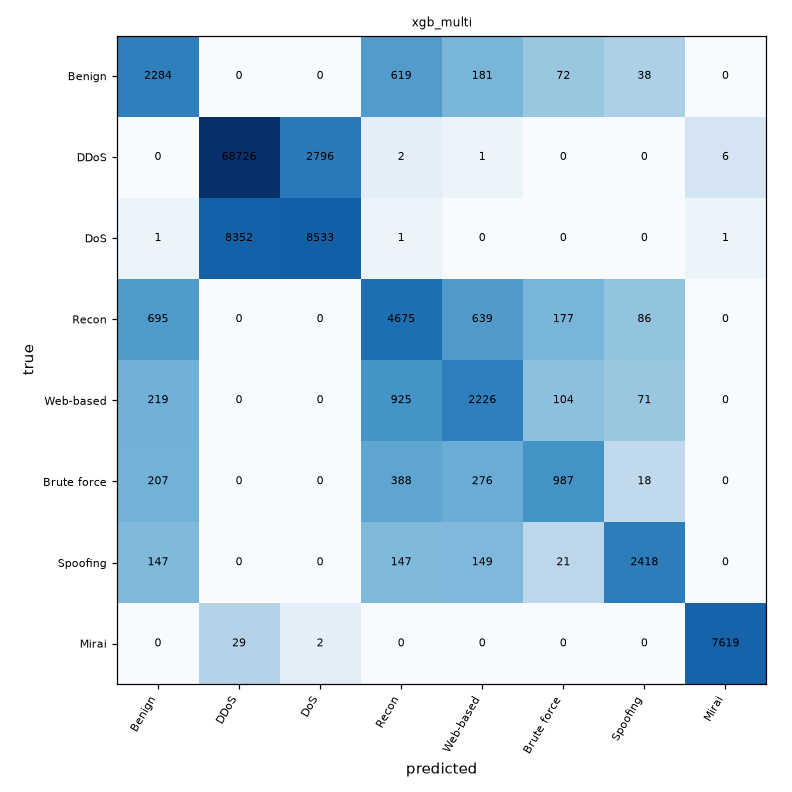

In [7]:
m = pd.DataFrame([jload(f) for f in sorted(glob.glob(str(RES / "metrics_*.json")))]).set_index("model_id")
base = [f"{n}_{t}" for t in ("binary", "multi") for n in ("dt", "rf", "xgb", "mlp")]
display(m.loc[base, ["task", "macro_f1", "accuracy", "precision", "recall", "fpr"]])
display(m.loc[[b for b in base if b.endswith("multi")], [c for c in m.columns if c.startswith("f1_")]])
for b in ("xgb_binary", "xgb_multi"):
    display(Markdown(f"confusion matrix `{b}` (csv + png for every model in results/ and figures/)")); display(csv(f"cm_{b}.csv", index_col=0))
display(Image(str(FIG / "cm_xgb_multi.png")))

FPR: binary = FP/(FP+TN) with *attack* as positive (benign flows flagged as attack); multiclass = macro-averaged one-vs-rest. Predictions of every model are saved (`results/pred_*.npz`), and `verify.py` recomputes all metrics from them.

## 8. Resource measurements

In [8]:
cols = ["model_id", "size_kb", "peak_rss_mb", "peak_rss_increase_mb", "cpu_util_pct", "lat_mean_ms", "lat_median_ms", "lat_p95_ms", "lat_p99_ms", "throughput_b1024_per_s", "oom"]
for tag, title in (("docker", "OFFICIAL: Docker --cpus=1 --memory=1g (one container per model)"), ("native", "SECONDARY: native, not Docker-limited, pinned to one core")):
    b = csv(f"benchmark_{tag}.csv"); display(Markdown(f"**{title}**"))
    display(b[[c for c in cols if c in b]][b.model_id.isin(base)].set_index("model_id"))

**OFFICIAL: Docker --cpus=1 --memory=1g (one container per model)**

,size_kb,peak_rss_mb,peak_rss_increase_mb,cpu_util_pct,lat_mean_ms,lat_median_ms,lat_p95_ms,lat_p99_ms,throughput_b1024_per_s,oom
model_id,,,,,,,,,,
dt_binary,718.5244,131.3359,0.2266,99.9416,0.1806,0.1613,0.2794,0.4374,4455631.8714,NaN
dt_multi,2763.8057,136.5977,0.1680,99.6046,0.1730,0.1593,0.2467,0.3646,3070750.2047,NaN
mlp_binary,183.6533,565.7305,0.4102,99.9929,1.9075,1.8631,2.1842,2.5760,403029.2529,NaN
mlp_multi,189.0049,568.5898,0.4023,100.0207,2.0017,1.9540,2.3012,2.7175,371167.3309,NaN
rf_binary,139890.0244,406.6602,0.1719,100.0241,4.5935,4.4632,5.2923,6.4537,76127.5911,NaN
rf_multi,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
xgb_binary,5490.2051,206.2266,0.1914,100.0158,0.5524,0.5417,0.6482,0.7371,157083.0416,NaN
xgb_multi,43513.8564,642.8906,0.1602,99.9979,4.2194,4.0194,5.4704,5.8707,19740.7188,NaN


**SECONDARY: native, not Docker-limited, pinned to one core**

,size_kb,peak_rss_mb,peak_rss_increase_mb,cpu_util_pct,lat_mean_ms,lat_median_ms,lat_p95_ms,lat_p99_ms,throughput_b1024_per_s
model_id,,,,,,,,,
dt_binary,718.5244,160.5703,0.3828,98.8724,0.1428,0.1397,0.1566,0.1953,4841608.0079
dt_multi,2763.8057,164.1055,0.2422,99.2908,0.1429,0.1408,0.1530,0.1797,3177164.0398
mlp_binary,183.6533,373.9688,0.4609,99.3031,2.1690,2.1279,2.3857,2.5553,366302.9821
mlp_multi,189.0049,374.8164,1.0703,99.0557,2.2585,2.2078,2.5000,2.7475,347472.0088
rf_binary,139890.0244,434.7188,0.4258,99.5622,4.9414,4.8675,5.2568,5.8805,73332.2116
rf_multi,1431589.3057,2958.4414,0.3047,99.3868,5.0017,4.9502,5.3319,5.9675,23273.8863
xgb_binary,5490.2051,218.0273,0.4102,97.3128,0.6751,0.6586,0.7612,0.8582,134589.8565
xgb_multi,43513.8564,649.0352,0.5898,99.6208,5.0891,4.9151,6.1070,6.4238,17151.3658


Each model runs in its own fresh process/container, 1 thread everywhere, 20,000 saved test rows as input, 200 warm-ups, 10,000 single-flow predictions, ≥25 batch-1024 repeats. A model that exceeds the 1 GB limit is recorded as OOM, not re-run with more memory. Docker on a laptop is not a Raspberry Pi.

## 9. Model reduction

In [9]:
g = csv("tree_reduction_grid.csv"); print("grid rows:", len(g), "(results/tree_reduction_grid.csv)")
display(csv("tree_selected_variants.csv", index_col=0)[["k", "rank", "depth", "n_est", "val_macro_f1", "baseline_val_f1", "size_kb", "lat_ms"]])
d = jload(RES / "mlp_quant_choice.json"); display(pd.DataFrame({k: {"chosen": v["chosen"]} for k, v in d.items()}).T)
mm = m[m.index.str.startswith("mlp_") & ~m.index.str.contains("_s4")]
display(mm[["task", "macro_f1", "val_macro_f1", "sparsity", "size_raw_kb", "size_gzip_kb", "quant_mode", "T", "alpha"]].sort_index())
for t in ("binary", "multi"): print(t, "distillation search:", json.dumps(jload(RES / f"distill_search_{t}.json")))

grid rows: 552 (results/tree_reduction_grid.csv)


,k,rank,depth,n_est,val_macro_f1,baseline_val_f1,size_kb,lat_ms
dt_binary_mod,all,imp,5.0000,0,0.7728,0.7793,3.8369,0.1070
dt_binary_agg,all,imp,5.0000,0,0.7728,0.7793,3.8369,0.1070
rf_binary_mod,20,imp,12.0000,25,0.7949,0.8037,3283.8213,1.4557
rf_binary_agg,30,imp,12.0000,10,0.7900,0.8037,1241.9463,0.7618
xgb_binary_mod,all,mi,8.0000,100,0.8090,0.8172,784.0977,0.3553
xgb_binary_agg,20,mi,8.0000,25,0.7881,0.8172,198.4766,0.1424
dt_multi_mod,all,mi,15.0000,0,0.7016,0.7069,663.4307,0.1101
dt_multi_agg,all,mi,15.0000,0,0.7016,0.7069,663.4307,0.1101
rf_multi_mod,30,imp,NaN,25,0.7330,0.7407,353019.8057,1.3822
rf_multi_agg,30,imp,NaN,10,0.7215,0.7407,141547.6025,0.7010


,chosen
mlp_binary_q8,mlp_binary_q8
mlp_binary_distq8,mlp_binary_distq8
mlp_multi_q8,mlp_multi_q8dyn
mlp_multi_distq8,mlp_multi_distq8dyn


,task,macro_f1,val_macro_f1,sparsity,size_raw_kb,size_gzip_kb,quant_mode,T,alpha
model_id,,,,,,,,,
mlp_binary,binary,0.7800,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mlp_binary_ctrl,binary,0.7865,0.7837,NaN,NaN,NaN,NaN,NaN,NaN
mlp_binary_dist,binary,0.7813,0.7804,NaN,NaN,NaN,NaN,2.0000,0.5000
mlp_binary_distq8,binary,0.7912,0.7898,NaN,NaN,NaN,full-integer,NaN,NaN
mlp_binary_distq8dyn,binary,0.7814,0.7795,NaN,NaN,NaN,dynamic-range,NaN,NaN
mlp_binary_prune50,binary,0.7817,0.7792,0.5000,182.4492,105.9277,NaN,NaN,NaN
mlp_binary_prune70,binary,0.7805,0.7797,0.7010,182.4512,83.9033,NaN,NaN,NaN
mlp_binary_prune90,binary,0.7163,0.7164,0.8968,182.4512,49.1162,NaN,NaN,NaN
mlp_binary_q8,binary,0.7942,0.7943,NaN,NaN,NaN,full-integer,NaN,NaN


binary distillation search: {"grid": [{"T": 2, "alpha": 0.5, "val_macro_f1": 0.7803569981884231}, {"T": 4, "alpha": 0.5, "val_macro_f1": 0.7721316691176531}, {"T": 4, "alpha": 0.9, "val_macro_f1": 0.7704920839792981}], "best": {"T": 2, "alpha": 0.5, "val_macro_f1": 0.7803569981884231}, "control_val_macro_f1": 0.783749595341487, "teacher_val_macro_f1": 0.7855737216222602}
multi distillation search: {"grid": [{"T": 2, "alpha": 0.5, "val_macro_f1": 0.6844860152593581}, {"T": 4, "alpha": 0.5, "val_macro_f1": 0.6712243381628893}, {"T": 4, "alpha": 0.9, "val_macro_f1": 0.6671077954021888}], "best": {"T": 2, "alpha": 0.5, "val_macro_f1": 0.6844860152593581}, "control_val_macro_f1": 0.6877419482456902, "teacher_val_macro_f1": 0.7038804283957327}


Trees: top-k features (mutual information vs model importance), depth limits and fewer trees; *moderate* = smallest variant within 1 point of the baseline **validation** macro F1, *aggressive* = within 3 points. MLP: magnitude pruning 50/70/90% (manual masks + fine-tuning; unstructured sparsity does **not** shrink the dense file or speed up dense inference — only the gzip size drops), TFLite int8 (full-integer chosen vs dynamic-range on validation F1 and size only), distillation with a control student of identical architecture, and distilled+int8.

## 10. Final comparison

In [10]:
for tag in ("docker", "native"):
    display(Markdown(f"**Baselines — {tag}** (`results/baseline_comparison_{tag}.csv`)")); display(csv(f"baseline_comparison_{tag}.csv").set_index("model").T)
r = csv("reduced_vs_original_docker.csv")
display(Markdown("**Reduced vs original — Docker** (`results/reduced_vs_original_docker.csv`)"))
display(r.sort_values(["task", "family", "variant"]).set_index("model_id"))
display(Markdown("**Macro F1 over seeds 42/43/44** (`results/seed_stability.csv`; split fixed; XGBoost hist is deterministic so std=0)")); display(csv("seed_stability.csv"))

**Baselines — docker** (`results/baseline_comparison_docker.csv`)

model,Decision Tree,Random Forest,XGBoost,MLP
binary_macro_f1,0.7854,0.8021,0.8194,0.7800
binary_accuracy,0.9767,0.9813,0.9818,0.9793
binary_precision,0.7873,0.8577,0.8481,0.8333
binary_recall,0.7836,0.7622,0.7953,0.7421
binary_fpr,0.4211,0.4699,0.4023,0.5091
multi_macro_f1,0.7084,0.7404,0.7554,0.7103
multi_accuracy,0.8377,0.8241,0.8562,0.8409
multi_precision,0.7363,0.7563,0.7829,0.7459
multi_recall,0.6935,0.7326,0.7394,0.6926
multi_fpr,0.0382,0.0354,0.0343,0.0368


**Baselines — native** (`results/baseline_comparison_native.csv`)

model,Decision Tree,Random Forest,XGBoost,MLP
binary_macro_f1,0.7854,0.8021,0.8194,0.7800
binary_accuracy,0.9767,0.9813,0.9818,0.9793
binary_precision,0.7873,0.8577,0.8481,0.8333
binary_recall,0.7836,0.7622,0.7953,0.7421
binary_fpr,0.4211,0.4699,0.4023,0.5091
multi_macro_f1,0.7084,0.7404,0.7554,0.7103
multi_accuracy,0.8377,0.8241,0.8562,0.8409
multi_precision,0.7363,0.7563,0.7829,0.7459
multi_recall,0.6935,0.7326,0.7394,0.6926
multi_fpr,0.0382,0.0354,0.0343,0.0368


**Reduced vs original — Docker** (`results/reduced_vs_original_docker.csv`)

,family,task,variant,macro_f1,d_macro_f1,size_kb,size_kb_ratio,peak_rss_mb,peak_rss_mb_ratio,peak_rss_increase_mb,peak_rss_increase_mb_ratio,cpu_util_pct,cpu_util_pct_ratio,lat_mean_ms,lat_mean_ms_ratio,lat_median_ms,lat_median_ms_ratio,lat_p95_ms,lat_p95_ms_ratio,lat_p99_ms,lat_p99_ms_ratio,throughput_b1024_per_s,throughput_ratio
model_id,,,,,,,,,,,,,,,,,,,,,,,
dt_binary_agg,dt,binary,agg,0.7758,-0.0096,3.8213,0.0053,131.6055,1.0021,0.4258,1.8793,99.0678,0.9913,0.1044,0.5784,0.0970,0.6012,0.1403,0.5021,0.1748,0.3996,5370873.5013,1.2054
dt_binary,dt,binary,baseline,0.7854,0.0000,718.5244,1.0000,131.3359,1.0000,0.2266,1.0000,99.9416,1.0000,0.1806,1.0000,0.1613,1.0000,0.2794,1.0000,0.4374,1.0000,4455631.8714,1.0000
dt_binary_mod,dt,binary,mod,0.7758,-0.0096,3.8213,0.0053,131.3945,1.0004,0.4219,1.8621,100.0969,1.0016,0.1043,0.5778,0.0957,0.5933,0.1523,0.5450,0.2132,0.4874,5318706.8894,1.1937
mlp_binary,mlp,binary,baseline,0.7800,0.0000,183.6533,1.0000,565.7305,1.0000,0.4102,1.0000,99.9929,1.0000,1.9075,1.0000,1.8631,1.0000,2.1842,1.0000,2.5760,1.0000,403029.2529,1.0000
mlp_binary_ctrl,mlp,binary,ctrl,0.7865,0.0065,34.2061,0.1863,566.8789,1.0020,0.3984,0.9714,99.9885,1.0000,2.0625,1.0812,2.0086,1.0781,2.3937,1.0959,2.8062,1.0893,453652.7687,1.1256
mlp_binary_dist,mlp,binary,dist,0.7813,0.0014,34.2061,0.1863,567.1836,1.0026,0.3984,0.9714,99.9700,0.9998,2.0679,1.0841,2.0081,1.0778,2.4208,1.1083,2.8578,1.1094,327500.4773,0.8126
mlp_binary_distq8,mlp,binary,distq8,0.7912,0.0112,7.0312,0.0383,559.8984,0.9897,0.9297,2.2667,100.0556,1.0006,0.0062,0.0032,0.0052,0.0028,0.0116,0.0053,0.0126,0.0049,12629657.4927,31.3368
mlp_binary_distq8dyn,mlp,binary,distq8dyn,0.7814,0.0014,7.2109,0.0393,558.6562,0.9875,0.6680,1.6286,100.1706,1.0018,0.0069,0.0036,0.0057,0.0031,0.0120,0.0055,0.0227,0.0088,7771529.1842,19.2828
mlp_binary_prune50,mlp,binary,prune50,0.7817,0.0017,183.5508,0.9994,568.9102,1.0056,0.4062,0.9905,99.9768,0.9998,1.9436,1.0189,1.8844,1.0114,2.2533,1.0317,2.7318,1.0605,395213.8229,0.9806


**Macro F1 over seeds 42/43/44** (`results/seed_stability.csv`; split fixed; XGBoost hist is deterministic so std=0)

,task,config,n_seeds,macro_f1_mean,macro_f1_std,values
0,binary,dt,3,0.7846,0.0008,"[0.7854, 0.7838, 0.7847]"
1,binary,rf,3,0.8020,0.0006,"[0.8021, 0.8013, 0.8025]"
2,binary,xgb,3,0.8194,0.0000,"[0.8194, 0.8194, 0.8194]"
3,binary,dt_mod,3,0.7758,0.0000,"[0.7758, 0.7758, 0.7758]"
4,binary,rf_mod,3,0.7931,0.0015,"[0.7914, 0.7939, 0.7941]"
5,binary,xgb_mod,3,0.8122,0.0000,"[0.8122, 0.8122, 0.8122]"
6,binary,mlp,3,0.7755,0.0114,"[0.78, 0.7625, 0.7839]"
7,binary,mlp_q8(chosen),3,0.7903,0.0069,"[0.7942, 0.7823, 0.7943]"
8,binary,mlp_dist,3,0.7767,0.0047,"[0.7813, 0.772, 0.7767]"
9,binary,mlp_ctrl,3,0.7709,0.0189,"[0.7865, 0.7499, 0.7763]"


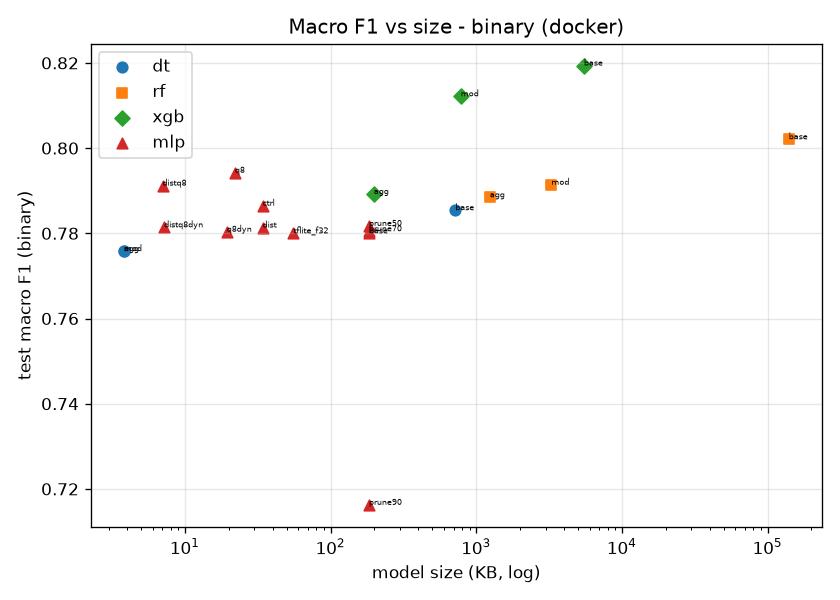

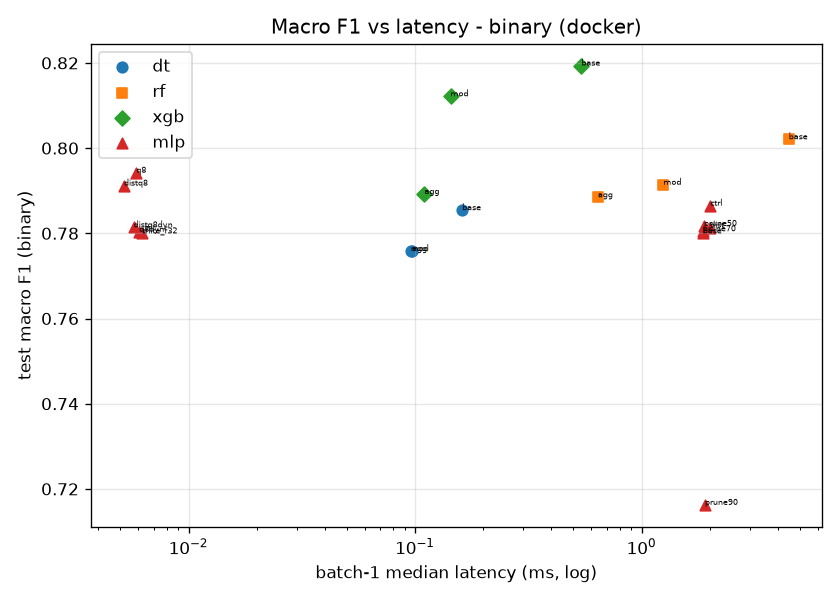

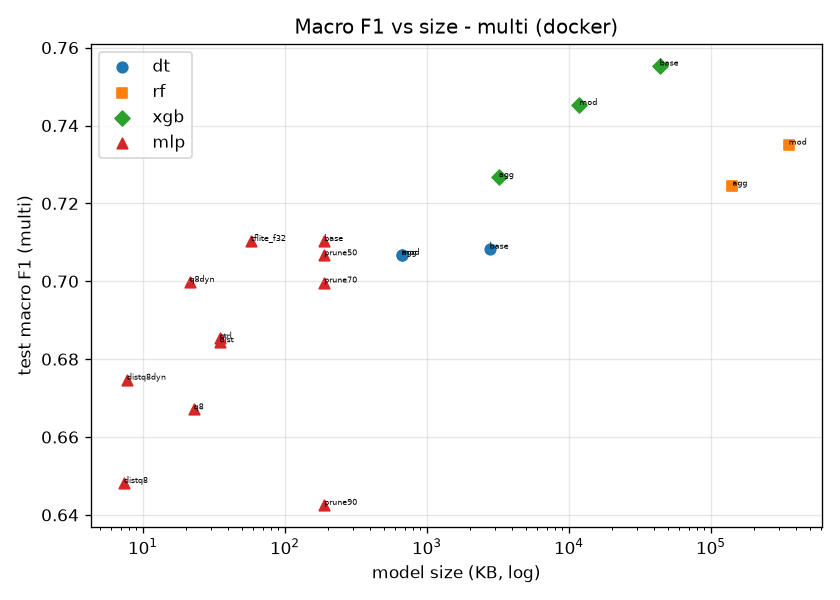

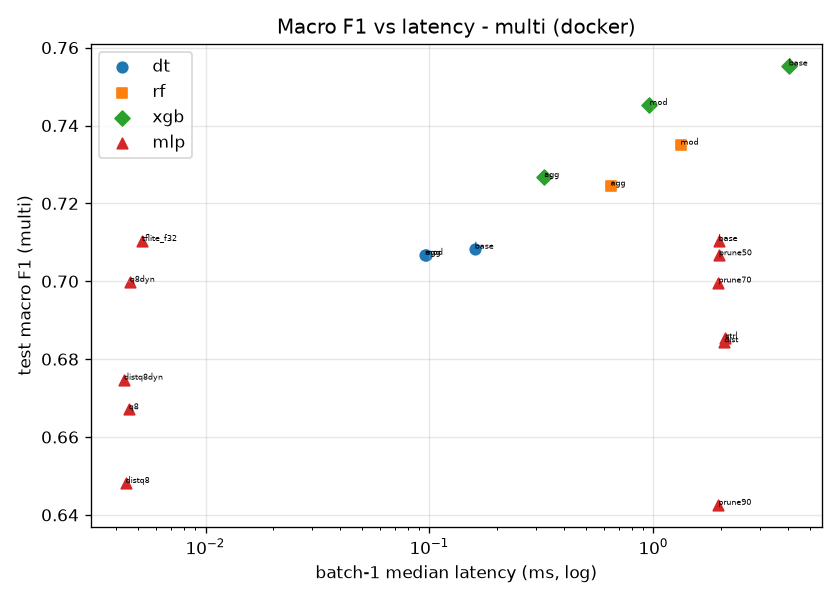

In [11]:
for t in ("binary", "multi"):
    for k in ("size", "latency"): display(Image(str(FIG / f"pareto_docker_{t}_{k}.png")))

## Conclusion
**Project question: which model and reduction lowers memory, CPU or inference time while keeping detection strong?** (official numbers: Docker, 1 CPU, 1 GB; `results/reduced_vs_original_docker.csv`)

* **Detection (test macro F1, `results/baseline_comparison_docker.csv`)**: XGBoost is best (binary 0.819, 8-class 0.755), then Random Forest (0.802 / 0.740), then the MLP (0.780 / 0.710) and Decision Tree (0.785 / 0.708). The DT-vs-MLP gap is smaller than the MLP's seed spread (std 0.011 binary), so those two are not separable. Absolute scores are modest (~0.8) because the cleaned data contains many nearly indistinguishable flows (identical vectors with conflicting labels were removed) and benign is rare; the binary FPR (benign flagged as attack) is high, 0.40-0.51, for every model.
* **Tree reduction works well.** `xgb_binary_mod` (depth 8, 100 trees): -0.7 pt macro F1, size 0.14x, batch-1 latency 0.27x, throughput 4.2x. `rf_binary_mod`: -1.1 pt, size 0.023x (140 MB to 3.3 MB), latency 0.28x. The most aggressive tree variants cost 1.4-3.0 pt (binary) for size 0.04-0.01x. `dt_binary_mod` (depth 5, 3.8 KB) loses 1.0 pt and is the smallest and fastest model overall (0.096 ms) but the weakest on quality. The multiclass Random Forest baseline (1.4 GB) runs out of memory at 1 GB; its reduced versions `rf_multi_mod` (353 MB) and `rf_multi_agg` (142 MB) fit.
* **Depth and tree count did most of the work** (`results/tree_reduction_grid.csv`). In the ranking ablation, mutual-information ranking beat model-importance ranking for RF/XGBoost (mean validation macro F1 0.78 vs 0.73, binary).
* **MLP**: magnitude pruning gives **no** size or speed gain for dense inference (only the gzip size shrinks) and 90% sparsity costs 6-7 pt. Distillation gave **no measurable benefit** over the same small student trained without it (binary 0.777 vs 0.771, 8-class 0.680 vs 0.676, 3 seeds, within seed noise). 8-bit TFLite shrinks the file ~8x (184 to 22 KB) with a task-dependent F1 change (binary +1.4 pt, noise level; 8-class full-integer -4.3 pt, dynamic-range -1.0 pt). The big MLP latency drop (1.86 ms to ~0.006 ms) comes mostly from switching from the Keras eager runtime to the TFLite interpreter: an *unquantised* float32 TFLite control already reaches 0.0063 ms; int8 adds ~1.9x only in batch-1024 throughput.
* **Memory**: RSS is dominated by the Python/library runtime (tree models ~131-410 MB, MLP with TensorFlow ~560 MB), not by the weights; RSS growth during prediction was under 0.5 MB. CPU utilisation is ~100% for every model (one busy thread), so it does not discriminate; CPU cost is better read from latency and throughput.
* **Overall**: for a gateway that needs a small, fast and accurate detector, a depth-limited XGBoost (`xgb_*_mod`) gives the best quality for its cost; a shallow Decision Tree is the cheapest if 1-1.5 pt more loss is acceptable. These conclusions come from one dataset, one split and Docker on a laptop, not a Raspberry Pi.

## Next phase: metaheuristic optimization
GA, PSO and ACO (plus a random-search control) were applied to all four models; method, results, resources and an honest discussion are in [`iot_ids_optimization.ipynb`](iot_ids_optimization.ipynb) and in the section *Optimization with GA, PSO and ACO* of `REPORT.md`. Nothing above this cell was changed.